# 01 - Classical Transformer Benchmark (Track A)

**Purpose.** Train and evaluate DeiT-Small, Swin-Tiny and MaxViT-Tiny (plus optional extras) with one data pipeline, one split manifest, one loss and one evaluation protocol. Model selection uses the validation split only.

**Requires (inputs).** Output of notebook 00 (split manifest) for the same MODE; RSNA data; optional offline timm weights dataset.

**Produces (outputs, under `/kaggle/working/rsna_ich_artifacts/<MODE>/`).** `experiments/A_<model>/` (best/last checkpoints, history, val/test predictions, thresholds, metrics, CIs), `selection/best_transformer.json`, optional ablation H `experiments/H_<model>_brain3/`.

> Research software. Outputs are model predictions for a research study and **not** clinical diagnoses.
> Results in this notebook are only valid for the MODE they were produced in (`smoke` results check correctness and say nothing about performance).

In [1]:
# ==== Setup: locate the project code and make `src` importable ====================================
# Works on Kaggle (project code attached as a Dataset, possibly nested after zip extraction) and locally.
import os, sys, importlib
from pathlib import Path

def find_project_root(max_depth: int = 5) -> Path:
    def ok(p: Path) -> bool:
        return (p / "src" / "__init__.py").is_file() and (p / "configs" / "data_config.yaml").is_file()
    cands = []
    if os.environ.get("RSNA_ICH_PROJECT_ROOT"):
        cands.append(Path(os.environ["RSNA_ICH_PROJECT_ROOT"]))
    cands += [Path.cwd(), Path.cwd().parent, Path("/kaggle/working/RSNA_ICH_Research")]
    for c in cands:
        if ok(c):
            return c.resolve()
    for base in (Path("/kaggle/input"), Path("/kaggle/working")):
        if not base.exists():
            continue
        stack = [(base, 0)]
        while stack:
            d, depth = stack.pop()
            if ok(d):
                return d.resolve()
            if depth < max_depth:
                try:
                    stack += [(p, depth + 1) for p in d.iterdir() if p.is_dir() and not p.name.startswith("stage_2_")]
                except OSError:
                    pass
    raise FileNotFoundError(
        "Project code not found. On Kaggle: 'Add Input' -> the dataset containing RSNA_ICH_Research "
        "(with src/ and configs/). Locally: run the notebook from RSNA_ICH_Research/notebooks or set "
        "the RSNA_ICH_PROJECT_ROOT environment variable.")

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
for _m in ["src", "src.utils.context", "src.data", "src.models", "src.quantum", "src.training", "src.evaluation"]:
    importlib.import_module(_m)  # fails loudly here if a dependency is missing
import src
print(f"Project root: {PROJECT_ROOT}  |  src version {src.__version__}")

Project root: /kaggle/input/datasets/mehulkhannaa/rsna-ich-research-code/RSNA_ICH_Research  |  src version 1.0.0


In [2]:
# ==== Optional dependencies ======================================================================
# Kaggle images ship torch, timm, pydicom, scikit-learn and OpenCV. PennyLane is only needed for the
# reference quantum backend (the default torch simulator does not need it). With internet enabled:
#   !pip install -q pennylane
# Without internet, attach a dataset of wheels and run: !pip install --no-index --find-links /kaggle/input/<wheels> pennylane
from src.utils.runtime import package_versions
print(package_versions())

{'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'timm': '1.0.30', 'pennylane': 'unavailable (ModuleNotFoundError)', 'pydicom': '3.0.2', 'numpy': '2.1.3', 'pandas': '2.3.3', 'sklearn': '1.6.1', 'scipy': '1.16.3', 'matplotlib': '3.10.0', 'yaml': '6.0.3', 'cv2': '4.14.0'}


In [3]:
# ==== Configuration ================================================================================
# MODE: "smoke" (correctness check, minutes) | "pilot" (representative subset) | "full" (largest feasible).
MODE = "pilot"
# Optional per-config overrides without editing YAML, e.g. {"transformer": {"train": {"epochs": 2}}}
OVERRIDES = {}
import json
if os.environ.get("RSNA_ICH_OVERRIDES_JSON"):          # test hook used by tools/run_notebooks_synthetic.py
    OVERRIDES = json.loads(os.environ["RSNA_ICH_OVERRIDES_JSON"])
MODE = os.environ.get("RSNA_ICH_MODE", MODE)

from src.utils.context import ProjectContext
ctx = ProjectContext(PROJECT_ROOT, MODE, OVERRIDES)
print(ctx.describe())
print("Installed packages:", ctx.runtime.packages)
ctx.save_run_info("01_transformers")

ProjectContext(mode=pilot, root=/kaggle/input/datasets/mehulkhannaa/rsna-ich-research-code/RSNA_ICH_Research, output=/kaggle/working/rsna_ich_artifacts/pilot)
  GPU: Tesla T4 (15.6 GB), Tesla T4 (15.6 GB) | CUDA=True bf16=False | CPUs=4 | RAM avail=31.76 GB | free disk (/kaggle/working/rsna_ich_artifacts)=20.94 GB
Installed packages: {'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'timm': '1.0.30', 'pennylane': 'unavailable (ModuleNotFoundError)', 'pydicom': '3.0.2', 'numpy': '2.1.3', 'pandas': '2.3.3', 'sklearn': '1.6.1', 'scipy': '1.16.3', 'matplotlib': '3.10.0', 'yaml': '6.0.3', 'cv2': '4.14.0'}


PosixPath('/kaggle/working/rsna_ich_artifacts/pilot/run_info/01_transformers.json')

In [4]:
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import display
from src import LABELS
from src.utils.io import atomic_write_json, atomic_save_dataframe, read_json, dataframe_to_markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

## 1. Load the shared split manifest and configuration

In [5]:
manifest, man_info = ctx.manifest()
ctx.restore_experiments(("A_", "H_"))  # resume interrupted runs from an attached previous version
tcfg = ctx.cfg["transformer"]
print("manifest", man_info["manifest_hash"][:12], "| grouping:", man_info["grouping_level"], "| images:", len(manifest))
print("Runtime:", ctx.runtime.summary())
models = list(tcfg["models"]) + [m for m in tcfg.get("optional_models", []) if m["name"] in tcfg.get("run_optional", [])]
print("Planned models:", [m["name"] for m in models])

manifest 749222703ee2 | grouping: patient | images: 61059
Runtime: GPU: Tesla T4 (15.6 GB), Tesla T4 (15.6 GB) | CUDA=True bf16=False | CPUs=4 | RAM avail=31.76 GB | free disk (/kaggle/working/rsna_ich_artifacts)=20.94 GB
Planned models: ['deit_small', 'swin_tiny', 'maxvit_tiny']


## 2. Train / evaluate each model (restartable)
A failure (missing weights, incompatible timm, OOM) is recorded and the loop continues. Completed experiments with an identical configuration are loaded, not retrained. Weight status is reported for every model.

In [6]:
from src.training.experiment import run_image_experiment
results = {}
for m in models:
    m = {**m, "weights_dir": tcfg.get("weights_dir")}
    exp_id = f"A_{m['name']}"
    print("=" * 100, "\n", exp_id)
    results[exp_id] = run_image_experiment(
        ctx, exp_id, m, tcfg["train"], tcfg["loss"], manifest=manifest, manifest_info=man_info,
        preprocess=ctx.cfg["data"]["preprocessing"], augment=ctx.cfg["data"]["augmentation"], limits=tcfg["limits"],
        loader_cfg=tcfg["loader"], threshold_method=tcfg["threshold_method"], n_boot=tcfg["n_boot"], seed=tcfg["seed"])

 A_deit_small


model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

[A_deit_small] built deit_small_patch16_224: status=pretrained params=21.7M
[A_deit_small] device=cuda batch=64 workers=3 amp=True(float16) train/val/test images=42889/8618/9552


/kaggle/input/datasets/mehulkhannaa/rsna-ich-research-code/RSNA_ICH_Research/src/training/trainer.py:283: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  tot += float(loss) * cfg.accum_steps * len(x)


  step 200/670 loss=0.4741
  step 400/670 loss=0.3960
  step 600/670 loss=0.3634
[epoch 1/3] train_loss=0.3557 val_loss=0.2914 val_macro_auc=0.9359 * (1555s)
  step 200/670 loss=0.2286
  step 400/670 loss=0.2274
  step 600/670 loss=0.2253
[epoch 2/3] train_loss=0.2240 val_loss=0.2641 val_macro_auc=0.9479 * (129s)
  step 200/670 loss=0.1491
  step 400/670 loss=0.1510
  step 600/670 loss=0.1470
[epoch 3/3] train_loss=0.1469 val_loss=0.3076 val_macro_auc=0.9430  (129s)
[trainer] early stopping at epoch 3 (no improvement for 1 epochs)
 A_swin_tiny


... (2 outputs left out)

[A_swin_tiny] built swin_tiny_patch4_window7_224: status=pretrained params=27.5M
[A_swin_tiny] device=cuda batch=64 workers=3 amp=True(float16) train/val/test images=42889/8618/9552
  step 200/670 loss=0.4872
  step 400/670 loss=0.4013
  step 600/670 loss=0.3638
[epoch 1/3] train_loss=0.3543 val_loss=0.2680 val_macro_auc=0.9419 * (244s)
  step 200/670 loss=0.2224
  step 400/670 loss=0.2214
  step 600/670 loss=0.2193
[epoch 2/3] train_loss=0.2176 val_loss=0.2451 val_macro_auc=0.9540 * (243s)
  step 200/670 loss=0.1544
  step 400/670 loss=0.1546
  step 600/670 loss=0.1518
[epoch 3/3] train_loss=0.1512 val_loss=0.2715 val_macro_auc=0.9502  (243s)
[trainer] early stopping at epoch 3 (no improvement for 1 epochs)
 A_maxvit_tiny


model.safetensors: reconstructing file:   0%|          |  0.00B /  124MB            

model.safetensors: downloading bytes:           |  0.00B            

[A_maxvit_tiny] built maxvit_tiny_tf_224: status=pretrained params=30.4M
[A_maxvit_tiny] device=cuda batch=64 workers=3 amp=True(float16) train/val/test images=42889/8618/9552
  step 200/670 loss=0.5443
  step 400/670 loss=0.4310
  step 600/670 loss=0.3859
[epoch 1/3] train_loss=0.3737 val_loss=0.2814 val_macro_auc=0.9387 * (451s)
  step 200/670 loss=0.2364
  step 400/670 loss=0.2324
  step 600/670 loss=0.2289
[epoch 2/3] train_loss=0.2289 val_loss=0.2435 val_macro_auc=0.9577 * (450s)
  step 200/670 loss=0.1827
  step 400/670 loss=0.1842
  step 600/670 loss=0.1827
[epoch 3/3] train_loss=0.1824 val_loss=0.2422 val_macro_auc=0.9571  (450s)
[trainer] early stopping at epoch 3 (no improvement for 1 epochs)


## 3. Benchmark table (sorted by **validation** macro ROC-AUC; test columns are reported, never used for selection)

In [7]:
def row(exp_id, r):
    out = {"experiment": exp_id, "status": r.get("status"), "weights": (r.get("build") or {}).get("status"),
           "params_M": round((r.get("build") or {}).get("n_params", 0) / 1e6, 1)}
    if r.get("status") == "succeeded":
        ci = r.get("test_macro_auc_ci", {})
        out.update(val_macro_auc=r["val_metrics"]["macro_roc_auc"], test_macro_auc=r["test_metrics"]["macro_roc_auc"],
                   test_ci=f"[{ci.get('ci_low', np.nan):.3f}, {ci.get('ci_high', np.nan):.3f}]",
                   test_macro_ap=r["test_metrics"]["macro_ap"], test_any_auc=r["test_metrics"].get("any_roc_auc"),
                   best_epoch=r["fit"]["best_epoch"], epochs_run=r["fit"]["epochs_run"], train_min=round(r["seconds_total"] / 60, 1))
    else:
        out["reason"] = r.get("error") or r.get("reason")
    return out
bench = pd.DataFrame([row(k, v) for k, v in results.items()])
if "val_macro_auc" in bench:
    bench = bench.sort_values("val_macro_auc", ascending=False, na_position="last")
display(bench)
atomic_save_dataframe(bench, ctx.dir("analysis") / "trackA_benchmark.csv")

,experiment,status,weights,params_M,val_macro_auc,test_macro_auc,test_ci,test_macro_ap,test_any_auc,best_epoch,epochs_run,train_min
2,A_maxvit_tiny,succeeded,pretrained,30.4,0.957709,0.922110,"[0.867, 0.959]",0.598034,0.948853,1,3,26.0
1,A_swin_tiny,succeeded,pretrained,27.5,0.953969,0.913181,"[0.873, 0.957]",0.599418,0.945466,1,3,14.2
0,A_deit_small,succeeded,pretrained,21.7,0.947925,0.911360,"[0.871, 0.950]",0.584953,0.941762,1,3,41.0


PosixPath('/kaggle/working/rsna_ich_artifacts/pilot/analysis/trackA_benchmark.csv')

## 4. Per-label results, training curves and ROC/PR curves (held-out test, frozen validation thresholds)

,label,n_pos,roc_auc,average_precision,sensitivity,specificity,precision,f1,brier,threshold,undefined
0,epidural,37,0.7571,0.0129,0.4595,0.9054,0.0185,0.0356,0.0122,0.0543,NaN
1,intraparenchymal,459,0.9587,0.7628,0.8802,0.9217,0.3620,0.5130,0.0384,0.2884,NaN
2,intraventricular,380,0.9698,0.7221,0.9132,0.9236,0.3311,0.4860,0.0276,0.1392,NaN
3,subarachnoid,628,0.9200,0.6041,0.8376,0.8410,0.2704,0.4089,0.0533,0.1399,NaN
4,subdural,611,0.9208,0.5787,0.8298,0.8403,0.2620,0.3983,0.0595,0.2268,NaN
5,any,1472,0.9418,0.8292,0.8268,0.9101,0.6264,0.7127,0.0639,0.3336,NaN


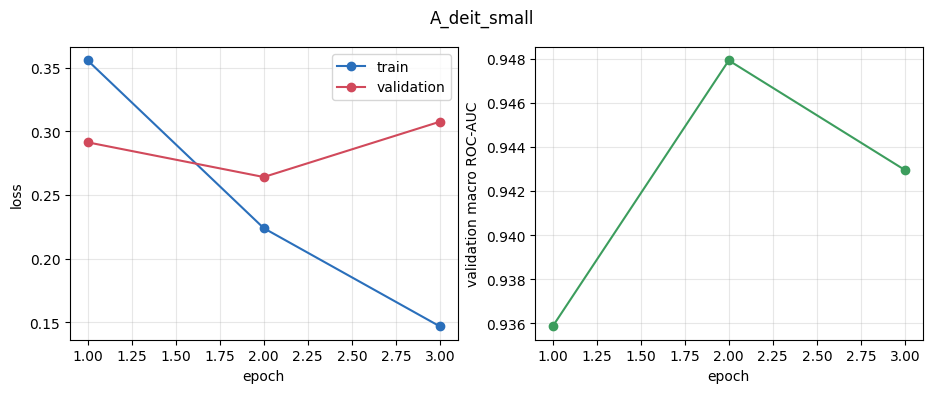

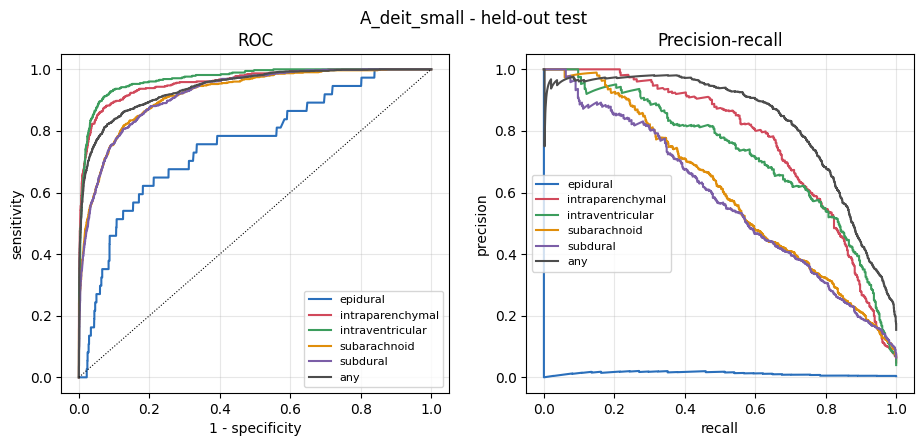

,label,n_pos,roc_auc,average_precision,sensitivity,specificity,precision,f1,brier,threshold,undefined
0,epidural,37,0.7376,0.0138,0.3784,0.8705,0.0112,0.0218,0.0140,0.0287,NaN
1,intraparenchymal,459,0.9649,0.7776,0.8911,0.9287,0.3869,0.5396,0.0358,0.2778,NaN
2,intraventricular,380,0.9709,0.7185,0.9158,0.9254,0.3372,0.4929,0.0249,0.1426,NaN
3,subarachnoid,628,0.9289,0.6450,0.8487,0.8594,0.2981,0.4412,0.0476,0.1395,NaN
4,subdural,611,0.9314,0.6015,0.8101,0.8879,0.3307,0.4696,0.0516,0.2655,NaN
5,any,1472,0.9455,0.8401,0.8193,0.9316,0.6856,0.7465,0.0597,0.4003,NaN


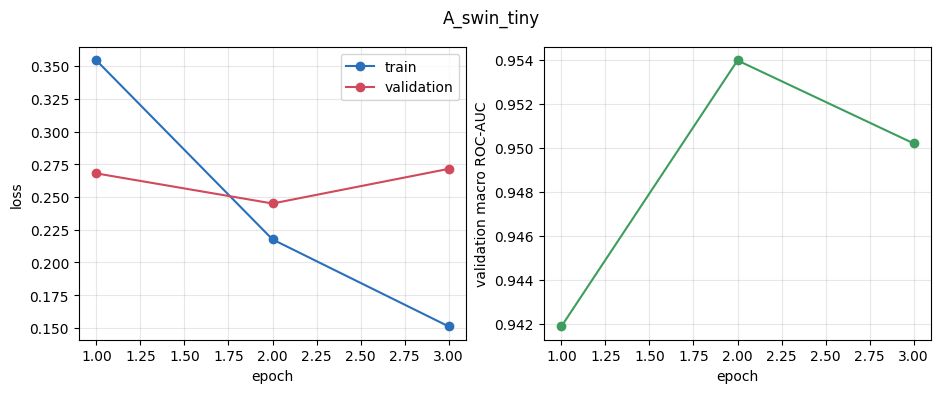

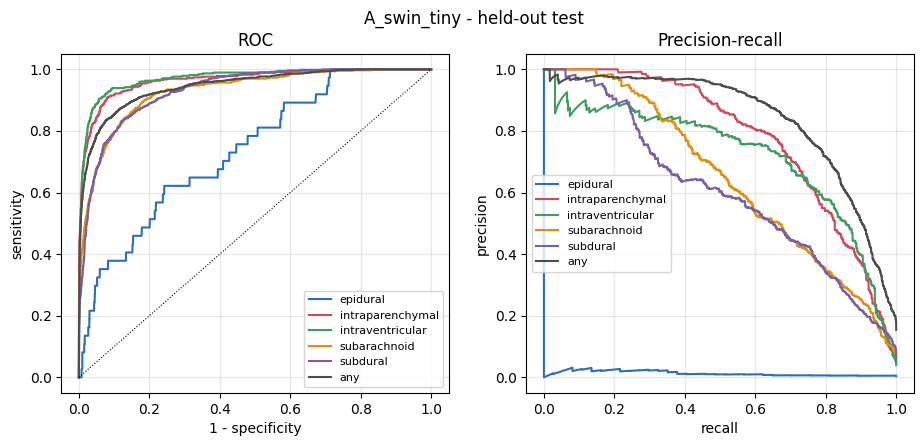

,label,n_pos,roc_auc,average_precision,sensitivity,specificity,precision,f1,brier,threshold,undefined
0,epidural,37,0.7825,0.0212,0.5946,0.9023,0.0231,0.0445,0.0131,0.0801,NaN
1,intraparenchymal,459,0.9697,0.7911,0.9020,0.9290,0.3906,0.5451,0.0346,0.2978,NaN
2,intraventricular,380,0.9703,0.7083,0.8632,0.9447,0.3928,0.5399,0.0303,0.3340,NaN
3,subarachnoid,628,0.9346,0.6335,0.8264,0.8915,0.3490,0.4908,0.0573,0.3398,NaN
4,subdural,611,0.9267,0.5856,0.8347,0.8604,0.2901,0.4306,0.0610,0.2864,NaN
5,any,1472,0.9489,0.8486,0.8499,0.9085,0.6286,0.7227,0.0666,0.4191,NaN


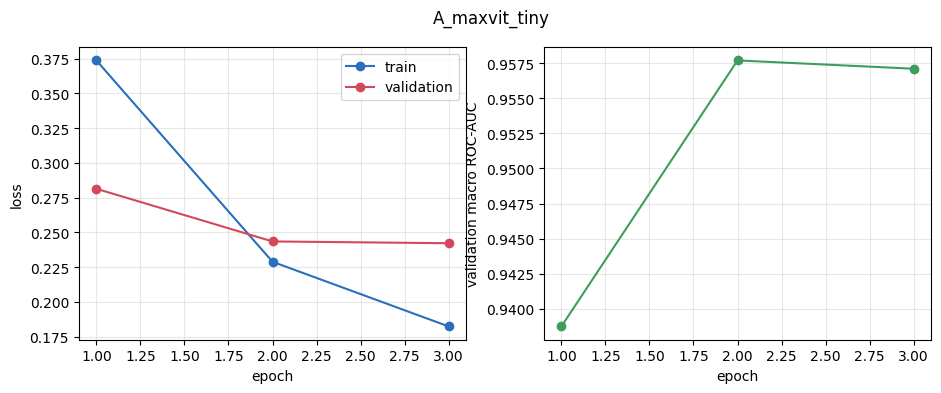

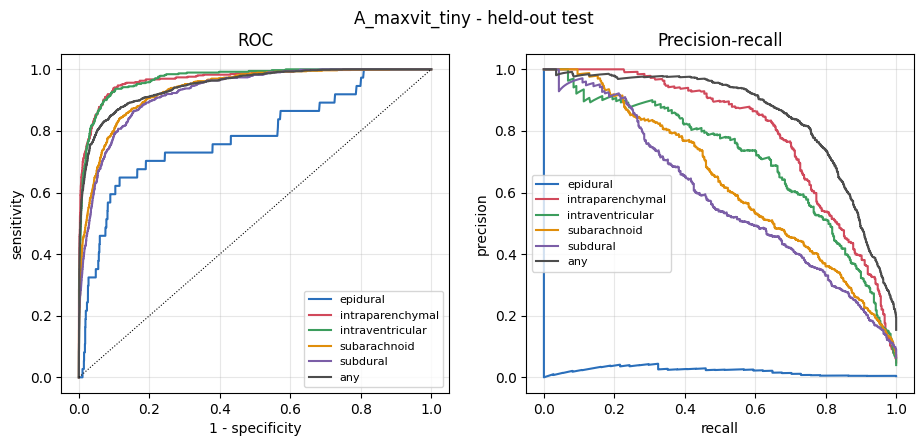

In [8]:
from src.evaluation.visualization import plot_history, plot_roc_pr
from src.evaluation.predictions import load_predictions, arrays
for exp_id, r in results.items():
    if r.get("status") != "succeeded":
        continue
    d = ctx.dir("experiments", exp_id)
    display(pd.read_csv(d / "metrics_test_per_label.csv")[["label", "n_pos", "roc_auc", "average_precision", "sensitivity",
                                                           "specificity", "precision", "f1", "brier", "threshold", "undefined"]].round(4))
    plot_history(pd.read_csv(d / "history.csv"), d / "history.png", exp_id); plt.show()
    pdf, _ = load_predictions(d / "predictions_test.parquet", man_info["manifest_hash"])
    p, t = arrays(pdf)
    plot_roc_pr(t, p, d / "roc_pr_test.png", f"{exp_id} - held-out test"); plt.show()

## 5. Select the best Transformer by validation macro ROC-AUC

In [9]:
from src.training.experiment import select_best_by_validation
best = select_best_by_validation(ctx, prefixes=("A_",))
if best is None:
    print("No Track-A experiment succeeded - nothing to select.")
else:
    sel = {"experiment_id": best["experiment_id"], "selected_by": "validation macro ROC-AUC",
           "val_macro_auc": best["val_metrics"]["macro_roc_auc"], "manifest_hash": man_info["manifest_hash"],
           "weights_status": best["build"]["status"]}
    atomic_write_json(ctx.dir("selection") / "best_transformer.json", sel)
    print(sel)

{'experiment_id': 'A_maxvit_tiny', 'selected_by': 'validation macro ROC-AUC', 'val_macro_auc': 0.9577086568106451, 'manifest_hash': '749222703ee2526ac5eb4e6c5c929c1a3bf7ac3b16b633dc0ad4c9c84201a34a', 'weights_status': 'pretrained'}


## 6. Ablation H - single-window vs multi-window input (best Transformer, identical budget)

In [10]:
if tcfg.get("ablation_single_window") and best is not None:
    mcfg = dict(best["config"]["model"]); mcfg.pop("in_chans", None)
    pp_single = {**ctx.cfg["data"]["preprocessing"], "channel_mode": "brain3"}
    exp_id = f"H_{mcfg['name']}_brain3"
    rH = run_image_experiment(ctx, exp_id, mcfg, tcfg["train"], tcfg["loss"], manifest=manifest, manifest_info=man_info,
                              preprocess=pp_single, augment=ctx.cfg["data"]["augmentation"], limits=tcfg["limits"],
                              loader_cfg=tcfg["loader"], threshold_method=tcfg["threshold_method"], n_boot=tcfg["n_boot"],
                              seed=tcfg["seed"])
    display(pd.DataFrame([row(best["experiment_id"] + " (bsb)", best), row(exp_id, rH)]))
else:
    ctx.registry.record("H_single_window", "skipped", reason="disabled in this MODE or no Track-A model succeeded")
    print("Ablation H skipped in this mode (recorded in the registry).")

[H_maxvit_tiny_brain3] built maxvit_tiny_tf_224: status=pretrained params=30.4M
[H_maxvit_tiny_brain3] device=cuda batch=64 workers=3 amp=True(float16) train/val/test images=42889/8618/9552


/kaggle/input/datasets/mehulkhannaa/rsna-ich-research-code/RSNA_ICH_Research/src/training/trainer.py:282: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  self.scheduler.step()


  step 200/670 loss=0.5463
  step 400/670 loss=0.4362
  step 600/670 loss=0.3907
[epoch 1/3] train_loss=0.3781 val_loss=0.2838 val_macro_auc=0.9391 * (653s)
  step 200/670 loss=0.2387
  step 400/670 loss=0.2325
  step 600/670 loss=0.2290
[epoch 2/3] train_loss=0.2283 val_loss=0.2456 val_macro_auc=0.9560 * (451s)
  step 200/670 loss=0.1745
  step 400/670 loss=0.1773
  step 600/670 loss=0.1751
[epoch 3/3] train_loss=0.1751 val_loss=0.2496 val_macro_auc=0.9544  (450s)
[trainer] early stopping at epoch 3 (no improvement for 1 epochs)


,experiment,status,weights,params_M,val_macro_auc,test_macro_auc,test_ci,test_macro_ap,test_any_auc,best_epoch,epochs_run,train_min
0,A_maxvit_tiny (bsb),succeeded,pretrained,30.4,0.957709,0.922110,"[0.867, 0.959]",0.598034,0.948853,1,3,26.0
1,H_maxvit_tiny_brain3,succeeded,pretrained,30.4,0.956020,0.920887,"[0.875, 0.958]",0.595275,0.945313,1,3,32.9


**Interpretation guidance.** Compare models on validation for selection; the test column with patient-level CIs is for reporting. Overlapping CIs mean the data cannot distinguish the models. Paired tests are in notebook 04.